MAGALY BENAVIDES SANTIAGO

Contruir un estimador recursivo de volatilidad EWMA para predecir la volatilidad futura a un horizonte de 5 sesiones en el ETS SPY 20215 2025. Donde evaluaremos las predicciones EWMA contra los 7 modelos base desarrlados en la semana 9 y sobre una misma muestra temporal. 

In [1]:
#importamos paqueterias 
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

entrada = Path("data/processed/SPY_2015_2025_targets.csv") #ruta de origen
salida = Path("results/semana_10") #ruta de salida 
salida.mkdir(parents=True, exist_ok=True) #crea la carpeta si aun no existe
if not entrada.exists():
  raise FileNotFoundError(entrada)
datos = pd.read_csv(entrada, index_col=0, parse_dates=True) #carga el archivo indicando que la columna 0 es el indice indexado 
assert isinstance(datos.index, pd.DatetimeIndex) #verifica que el indice sea de tipo fecha
assert datos.index.is_unique and datos.index.is_monotonic_increasing #verifica que este en orden cronologico y que sea unico
assert not datos.index.isna().any() #verifica que no tenga duplicados 
cols = ["Return", "Vol_5", "Vol_10", "Vol_20","Vol_30", "Target_Vol_5"] #comprueba que las columnas necesarias de rendimientos, volatilidades historicas y target esten presentes
assert set(cols).issubset(datos.columns) 
r = datos["Return"].to_numpy(dtype=float) #extrae los rendimientos diarios a un arreglo Numpy de punto flotante
assert len(r) > 100 and np.isfinite(r).all() #confirma que los ultimos 5 dias de dataset tenga valores nulos en la variable objetivo ya que el laas5 aun no se conocen 
h = 5 #asignamos el horizonte temporal de predicion 
objetivo = "Target_Vol_5"#define la cadena de texto con el nombre de la columna que contiene la volatilidad futura realizada que se busca predecir
y = datos[objetivo] #extrae la columna target_vol_5 del df como una serie 
assert y.iloc[-h:].isna().all() #comprueba que las ultimas h filas de la serie  y contengan unicamente valores nulos 
esperado = datos["Return"].rolling(h).std(ddof=1).shift(-h) #recalcula la desviacion estandar adelantada 5 dias para validar que coincidan de forma exacta con target_vol_5
np.testing.assert_allclose(y, esperado, rtol=1e-7,atol=1e-10, equal_nan=True) #realiza una auditoria comparando punto por punto la serie desde CSV y la serie esperado

##### RECURRENCIA SIN INFORMACIÓN FUTURA  
Define la funcion recursiva que calcula la volatilidad EWMA periodo por periodo sisn sesgo de informacion futura y junta en un solo DF todos los pronosticos de los 10 modelos (4 pronosticos de los 10 modelos, 3 promedios moviles y 3 variantes EWMA)

In [2]:
def ewma_pronostico(r, lam, inicial=30): #Funcion que toma la serie de retornos r, el factor de decaimiento (lam), y la ventana inicial
    r = np.asarray(r, dtype=float) #convierte la serie de netrada a un arreglo decimal flotante de alta precision
    assert 0 < lam < 1 and len(r) >= inicial # valida dos restricciones: decaimineto entre 0 y 1 para garantizar convergencia y #de observaciones debe ser mayor a 30 
    assert np.isfinite(r).all() #verifica que todos los valores dentro de la serie de retorno sean numericamnete infinitos
    pred = np.full(len(r), np.nan) #crea un vector de la misma longitud que la serie de retornos r iniciando cada posicion con el valor nulo 
    v = np.var(r[:inicial], ddof=1) #calcula la varianza muestral incondicional de la 1eras 30 observaciones, ddof grados de libertad(30-1=29)
    assert v >= 0 and np.isfinite(v) #revisa que el valor inicial de varianza obtenido sea positivo no nulo y valido 
    pred[inicial-1] = np.sqrt(v)#asigna la 1era estimacion de desviacion estandar a la posicion del indice 29 
    for i in range(inicial, len(r)): #inicia un iteracion secuencial desde el indice hasta el final del conjunto de datos
        v = lam * v + (1-lam) * r[i]**2 #actualiza el estado de la varianza integrando informacion del retorno 
        pred[i] = np.sqrt(v) #toma la raiz cuadrada de la nueva varianza condicional para convertila a unidades de desviacion estandar diaria 
    return pred #devuelve el arreglo completo con los pronosticos calculados 
pred = pd.DataFrame(index=datos.index) #crea un df vacio utilizando el mismo indice de fechas del dataset original 
for w in [5, 10, 20, 30]:#extrae del dataset las columnas de volatilidad historica calculadas sobre ventanas moviles y les asigna nombre HV5. HV 10...
    pred[f"HV{w}"] = datos[f"Vol_{w}"]
for k in [5, 10, 20]:
    pred[f"MA{k}"] = datos["Vol_5"].rolling(k).mean() #Construye los modelos de promedios moviles sobre volatilidad diaria  y suma lo valores de las ultimas k sesiones 
for lam, nombre in [(0.90, "EWMA90"),(0.94, "EWMA94"),(0.97, "EWMA97")]:#Ejecuta la funcion pasando la serie de retornos r para 3 valores distintos de factor de decaimiento
    pred[nombre] = ewma_pronostico(r, lam)
assert (pred.dropna() >= 0).all().all() #realiza una veriricacion global sobre todas las celdas validad del DF

In [12]:
pred.head(35)

,HV5,HV10,HV20,HV30,MA5,MA10,MA20,EWMA90,EWMA94,EWMA97
Date,,,,,,,,,,
2015-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-09,0.015351,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-12,0.012987,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-13,0.011958,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-14,0.010842,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-15,0.002494,NaN,NaN,NaN,0.010726,NaN,NaN,NaN,NaN,NaN


Observamos que los valores decimales muestran la volatilidad diaria estimada por cada modelos.   Los valores NaN representan el periodod de calnetamiento, debido a que cada modelo requiere cierta cantidada de datos pasados antes de emitir su primer resultado.  
- HV5, HV10: tardan 5, 10, etc dias cumulados en mostrar su primer calculo
- MA5, MA10: tardan mas tiempo porque requieren que HV5 ya exista para luego promediario en ventanas de 5, 10, etc dias
- EWMA90, EWMA94: Permanecen en NaN durante los 1eros 29 dias porque el algoritmo utiliza los 1eros 30 datos unicamnete para calcular la varianza base inical antes de actualizarse

In [3]:
#veriricacion manual de la recurrencia matematica
i = 50# selecciona un punto arbitrario 
for lam, nombre in [(0.90, "EWMA90"), (0.94, "EWMA94"),(0.97, "EWMA97")]: #inicia un bucle que pruebe consecutivamente las 3 variables del modelo EWMA 
    anterior = pred[nombre].iloc[i-1]**2 #extrae la estimacion de volatilidad del dia anterior en la posicion y la eleva al cuadrado para recuperar la varianza 
    calculado = np.sqrt(lam*anterior + (1-lam)*r[i]**2) #aplica manualmente desde cero la ecuacion de EWMA 
    np.testing.assert_allclose(pred[nombre].iloc[i],calculado, rtol=1e-12) #compara el valor calculado en la linea anterior contra el valor que habia guardado

# Prueba de causalidad: cambiar el futuro no cambia el pasado.
r_alt = r.copy() #dplica la serie original de retornos diarios en una nueva variable 
r_alt[i+1:] = 0.0 #modifica el retorno del dia siguiente asignandole un valor de cero
for lam, nombre in [(0.90, "EWMA90"),(0.94, "EWMA94"), (0.97, "EWMA97")]: #recorre nuevamente cada una de las 3 configuraciones de lam 
    alternativo = ewma_pronostico(r_alt, lam)#ejecuta la funcion utilizando la serie alterada 
    np.testing.assert_allclose(alternativo[:i+1],pred[nombre].to_numpy()[:i+1],equal_nan=True) #compara los pronosticos desde el dia 0 hasta 50 generados 

In [13]:
#Observamos que los resultados son los mismos
print(lam, pred)

0.97                  HV5      HV10      HV20      HV30       MA5      MA10  \
Date                                                                     
2015-01-05       NaN       NaN       NaN       NaN       NaN       NaN   
2015-01-06       NaN       NaN       NaN       NaN       NaN       NaN   
2015-01-07       NaN       NaN       NaN       NaN       NaN       NaN   
2015-01-08       NaN       NaN       NaN       NaN       NaN       NaN   
2015-01-09  0.015351       NaN       NaN       NaN       NaN       NaN   
...              ...       ...       ...       ...       ...       ...   
2025-12-24  0.002215  0.007143  0.005632  0.007697  0.006962  0.006380   
2025-12-26  0.003370  0.007123  0.005481  0.007698  0.006098  0.006354   
2025-12-29  0.003935  0.006152  0.005460  0.007032  0.005242  0.006097   
2025-12-30  0.003367  0.006139  0.005347  0.007040  0.004211  0.005791   
2025-12-31  0.004072  0.006634  0.005632  0.006952  0.003392  0.005549   

                MA20    EWMA90  

In [6]:
base = pd.concat([datos[[objetivo]], pred], axis=1) #une la volatilidad real observada cin el df de los 10 modelos
comun = base.dropna(subset=[objetivo] + pred.columns.tolist()) #elimina todas las filas que tengan al menos un valor nulo en cualquiera de los pronosticos
assert len(comun) > 100 #comprueba que la serie compartida contenga mas de 100 observaciones validad
assert np.isfinite(comun.to_numpy()).all() #comprueba que la matriz no tenga infinitos ni nulos en la matriz 
assert np.all(np.diff(datos.index.get_indexer(comun.index)) == 1) #valida que la secuencia de fechas dentro de la muestra comun sea estrictamente continua
corte = int(np.floor(0.70*len(comun)))#calcula la posicion entera que separa el 70% inicial de la muestra
fecha_inicio = comun.index[corte] #registra la fecha exacta donde arranca el bloque de prueba
fin_objetivo = pd.Series(datos.index, index=datos.index).shift(-h) #determina la fecha t el dia exacto en el que se completa la ventana de volatilidad real
inicial = comun.iloc[:corte] #selecciona el 1er 70% de la muestra como bloque preliminar 
desarrollo = inicial.loc[fin_objetivo.reindex(inicial.index) < fecha_inicio]#depura el conjunto de desarrolo para conservar unicamente las fechas cuyo periodo de 5 dias finalice
evaluacion = comun.iloc[corte:].copy() #asigna el 30% restante de la muestra de evaluacion fuera de entrenamiento
assert len(desarrollo) > 0
assert (fin_objetivo.loc[desarrollo.index] < fecha_inicio).all()

def metricas(y, p): #define una funcion para comparar el valor real y contra la prediccion p 
     y = np.asarray(y, dtype=float)
     p = np.asarray(p, dtype=float)
     e = y-p #error puntual 
     return {"N": len(y), "MAE": np.mean(np.abs(e)), #MAE error absoluto medio: mide la longitud promedio del error
         "RMSE": np.sqrt(np.mean(e**2)),"Sesgo": np.mean(e),"MAPE_pct": (100*np.mean(np.abs(e/y)) #RMSE:penaliza con mayor severidad las desviaciones grandes
                if np.all(y > 0) else np.nan), #sesgo: positivo> refleja subestimacion de la volatilidd real, negativo> indica sobreestimacion
             #MAPE> retorna NaN si hay valores y=0 para evitar division por cero
        "Objetivos_cero": int(np.sum(y == 0))} #conteo de dias donde la volatilidad objetivo fue exactamente 0

tabla = pd.DataFrame({m: metricas(evaluacion[objetivo],evaluacion[m]) #computa la funcion de los 10 modelos dentro de la evaluacion 
            for m in pred.columns}).T #traspone los datos para organizar los modelos en filas y metricas en columnas
tabla.index.name = "Modelo" #nombra al indice de la tabla como modelo
ref = tabla.loc["HV5", "RMSE"] #almacena la metrica RMSE del modelo base de referencia HV5 
tabla["Mejora_RMSE_pct_vs_HV5"] = (100*(1-tabla["RMSE"]/ref) if ref > 0 else np.nan) #calcula el porcentaje de reduccion del RMSE que logre cada modelos en compracion
print("Fechas:", evaluacion.index.min(), evaluacion.index.max())
print(tabla.sort_values("RMSE"))

Fechas: 2022-09-19 00:00:00 2025-12-23 00:00:00
            N       MAE      RMSE     Sesgo   MAPE_pct  Objetivos_cero  \
Modelo                                                                   
EWMA90  820.0  0.003504  0.005669 -0.000732  51.575068             0.0   
EWMA94  820.0  0.003642  0.005761 -0.000960  55.412113             0.0   
MA20    820.0  0.003427  0.005771 -0.000168  47.887697             0.0   
EWMA97  820.0  0.003896  0.005955 -0.001344  62.770414             0.0   
HV20    820.0  0.003589  0.006001 -0.000702  51.878193             0.0   
HV30    820.0  0.003683  0.006010 -0.000842  54.452087             0.0   
MA10    820.0  0.003547  0.006062 -0.000115  48.631070             0.0   
HV10    820.0  0.003689  0.006102 -0.000426  51.402582             0.0   
MA5     820.0  0.003741  0.006206 -0.000088  49.721446             0.0   
HV5     820.0  0.003933  0.006328 -0.000051  53.108692             0.0   

        Mejora_RMSE_pct_vs_HV5  
Modelo                        

Observamos que la prueba se realizo sobre 820 sesiones bursatiles del bloque fuerade muestra donde abarca del 19 de sep del 2022 al 23 de dic de 2025.  
El mejor modelo fue RMSE con EWMA90 porque obtuvo el mejor desempeno general logrando una raiz del error cuadratico medio mas baja y una ejor a de 10.42 %de precision predictiva respecto a HV5, lo que mantiene una memoria mas larga.  
La ponderacion exponencial supera casi todas las volatilidades historicas tradciones HV, lo qu valida la hipotesis de que los rendimientos recientes deben pesar mas que los lejanos al predecir la varianza futura.  
Sesgo: Todos lo modelos presentan un sesgo negativo, lo que significa que en promedio sobreestiman la volatilidad real observada en este periodo y genera mayor estimacion 

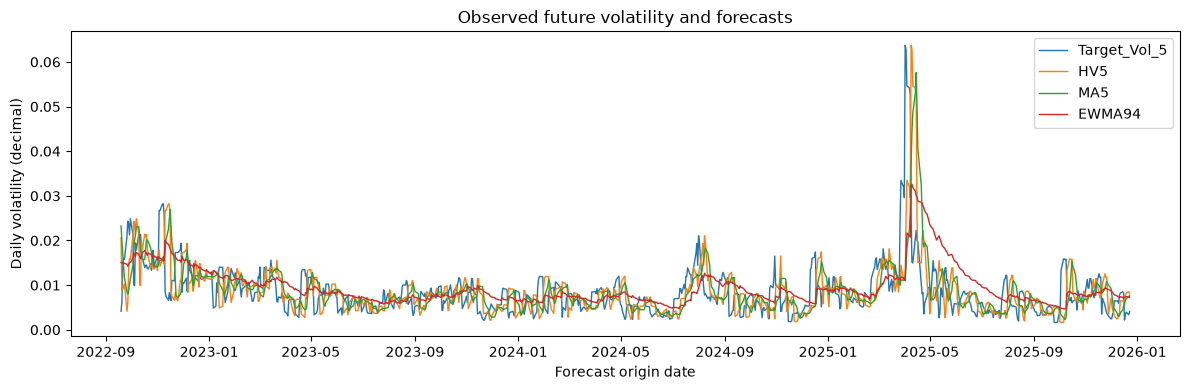

In [15]:
#GRAFICA 1: Volatilidad futura observada vs pronosticos
fig, ax = plt.subplots(figsize=(12, 4))
for m in [objetivo, "HV5", "MA5", "EWMA94"]:#itera sobre target_vol_5, la volatilidad historica(HV5), el promedio movil(MA5), y el modelo estandar exponecial (EWMA94)
    ax.plot(evaluacion.index, evaluacion[m], label=m, lw=1) #grafica eje horizontal el tiempo y vertical los valores de volatilidad de la columna m
ax.set(xlabel="Forecast origin date", #etiqueta el eje x como fecha de origen del pronostico
ylabel="Daily volatility (decimal)", #etiqueta de volatilidad diaria en decimales 
title="Observed future volatility and forecasts")
ax.legend() #despliega el cuadro de leyenda
fig.tight_layout() #ajusta los margenes automaticos de la figura para que quede encimado
fig.savefig(salida / "01_ewma_vs_baselines.png", dpi=180) #exporta la imagen en alta definiicion dentro de la carpeta:resultados semana 10
plt.show()

Comportamiento del mercado en target_vol_5: muestra picos reales de volatilidad del mercado, destacando un pico importante a medidados del 2025 donde la volatilidad diaria supera el 5.5%, además de episodios de menor turbulencia a finales de 2022 y mediados del 2024.   
- HV5: reacciona con picos bruscos y retrasados ante eventos extremos.
- MA5: suaviza los saltos diarios de HV5 al promediarlos
- EWMA94: Captura los incrementos de volatilidad rapidamente tras un choque de retornos y decae suavemente a medida que la calma regresa al mercado. 

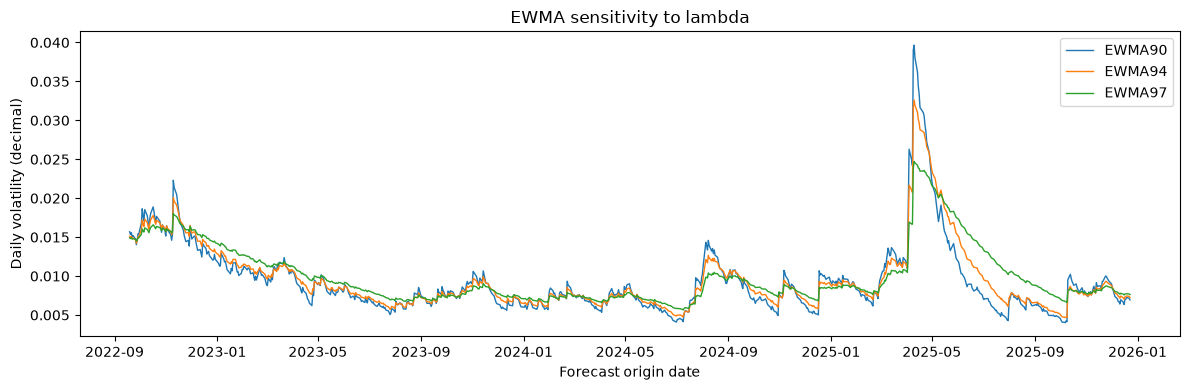

In [16]:
#GRAFICA 2: SENSIBILIDAD DE LAMBDA 
fig, ax = plt.subplots(figsize=(12, 4))
for m in ["EWMA90", "EWMA94", "EWMA97"]: #compara las tres variaciones de la ponderacion exponencial 
    ax.plot(evaluacion.index, evaluacion[m], label=m, lw=1)
ax.set(xlabel="Forecast origin date",
ylabel="Daily volatility (decimal)",
title="EWMA sensitivity to lambda")
ax.legend()
fig.tight_layout()
fig.savefig(salida / "02_sensibilidad_lambda.png", dpi=180)
plt.show()
#permite observar como lambda=0.90 genera picos mas reactivos ante choques recientes miestra que lambda=0.97 reproduce curvas mas suaves que suavisan  los cambios del mercado


-EWMA90: presenta los picos mas altos en periodos de crisis y decae mas rapido cuando el choque pasa. Al asignarle un paso de 10% al rednimiento del dia antewrior, responde con agilidad a noticias recientes.  
-EWMA97: es la curma mas suave, al mantener mayor memoria historica absorbe los choques puntuales con menor panico, pero consrva niveles elevados de volatilidad por mas tiempo tras un pico.   
-EWMA94: ofrece el punto media de equilibrio entre rapidez de respuesta y estabilidad. 

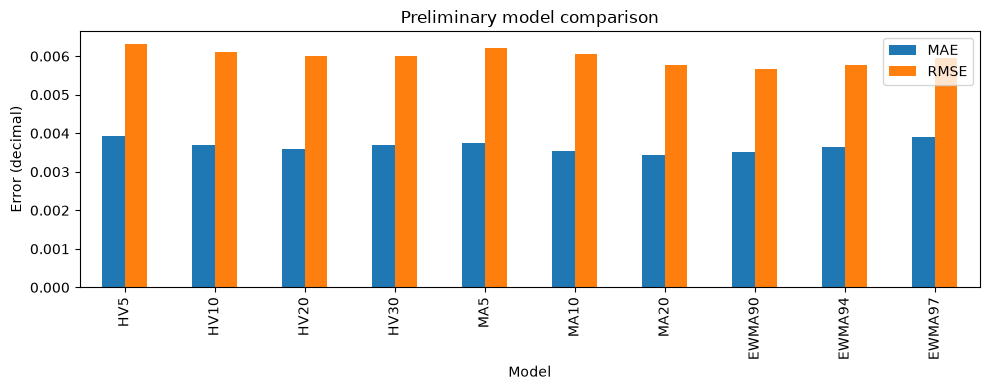

In [17]:
#GRAFICA 3: COMPARACION DE METRICAS DE ERROR
fig, ax = plt.subplots(figsize=(10, 4)) 
tabla[["MAE", "RMSE"]].plot.bar(ax=ax) #extrae unicamente las columnas MAE y RMSE de la tabl generada en el bloque 4 y las agrupa como barras. 
ax.set(xlabel="Model", ylabel="Error (decimal)",
title="Preliminary model comparison")
fig.tight_layout()
fig.savefig(salida / "03_metricas.png", dpi=180)
plt.show()

#EXPORTACION DE ARCHIVOS CSV
base.to_csv(salida / "SPY_2015_2025_ewma.csv") #exporta el dataframe completo con la serie temporal original, el target_vol_5 y las prediciones de los 10 modelos
evaluacion.to_csv(salida / "muestra_evaluacion.csv") #guarda unicamente las filas pertenecientes al bloque del 30% de prueba 
tabla.to_csv(salida / "metricas_ewma_y_bases.csv") #almacena la tabla reumen con las metricas cuantitativas
pd.DataFrame([{"Bloque": "desarrollo", "N": len(desarrollo),"Inicio": desarrollo.index.min(),"Fin": desarrollo.index.max()},
#crea un dataframe sintetico que registra las fechas de inicio , fechas de fin  y numero de observaciones N, para las muestras de desarrollo y evalucacion preliinar 
 {"Bloque": "evaluacion_preliminar","N": len(evaluacion),
"Inicio": evaluacion.index.min(),
"Fin": evaluacion.index.max()}]).to_csv(
salida / "periodos.csv", index=False)

PENALIZACION DE ERRORES GRANDES  
-Las volatilidades historicas cortas (HV5 Y HV10) registran los RMSE mas altos, evidenciando mayor imprecision cuando ocurre cambios bruscos en el mercado.  
-Los modelos EWMA, en especial EWMA90 logran las barras de RMSE mas bajas de todo el panel, confirmando que ponderar exponencialmente las observaciones reduce el error cuadrado frente a promedios simples.  
MAGNITUD PROMEDIO DEL ERROR  
-El error absoluto medio permanece relativamnete estable entre 0.0034 y 0.0039 en todas las alternativas sobresaliendo MA20 Y EWMA90 por mantenes los errores absolutos mas reducidos. 


CONCLUSIÓN  
El modelo EWMA demuestra que asignar mayor peso a los rendimientos recientes mejora significativamnete la predicción de volatilidad a 5 dias en el SPY en comparacion con los promedios hitoricos tradicionales. Observamos que el modelos ganador fue EWMA90 porqur obtuvo la mayor prescision del panel logrando reducir el error en un 10.42% respecto a la volatilidad historica base. En termnos de la respuesta tenemos que el factor de decaimiento que fue menor es lambda=90 porque permitio al mdelo reaccionar mas rapido a los choques de mercado, superando a las variantes con mayor memoria.  
En conclusion la ponderacion exponecial es superior a los promedios equiponderados para capturar la dinamica de la varianza condicional. 